# COU 07506 Digital Signal Processing — Week 01: Lab 0
## Setting Up the DSP Laboratory

**Name:** [YOUR NAME]  
**Registration No.:** [YOUR REGISTRATION NUMBER]  
**Class:** [BEng24COE / BEng24ETE / BEng24BEE — select yours]  
**Group:** [YOUR GROUP]  
**Date:** 24 November 2026  
**Instructor:** Dr. Haji Fimbombaya  
**Instructor checkpoint signed:** [ ] Checkpoint 1

Source: supplied *COU07506 DSP Laboratory Manual 2026/27*, printed pages 5–7
(PDF pages 6–8), with notebook conventions from printed pages 3 and 51.

This notebook covers Tasks 1.1–1.5. No voice recording was supplied, so the
saved outputs use the manual's permitted **synthetic fallback**, not a phone
recording. Replace the personal-information placeholders before submission.

## Pre-lab

Three example devices containing DSP are listed below. Edit these examples
to match devices you actually used today.

| Device | One signal it processes | Example DSP operation |
| --- | --- | --- |
| Smartphone | Microphone speech/audio | Noise reduction during calls |
| Laptop | Microphone audio | Echo cancellation during online meetings |
| Bluetooth headphones | Received digital audio | Equalization before playback |

Handout reading and account logins must be completed personally; neither is
claimed as verified here. The separate course handout was not provided.

## Task 1.1 — Your first notebook

Run the standard imports. All sequence amplitudes in Tasks 1.1 and 1.2 are
dimensionless. The horizontal axis is the integer sample index, not time in
seconds, because no sampling rate is assigned to these sequences.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from pathlib import Path
from IPython.display import Audio, display

plt.rcParams['figure.figsize'] = (9, 3.5)
output_dir = Path('outputs')
output_dir.mkdir(exist_ok=True)

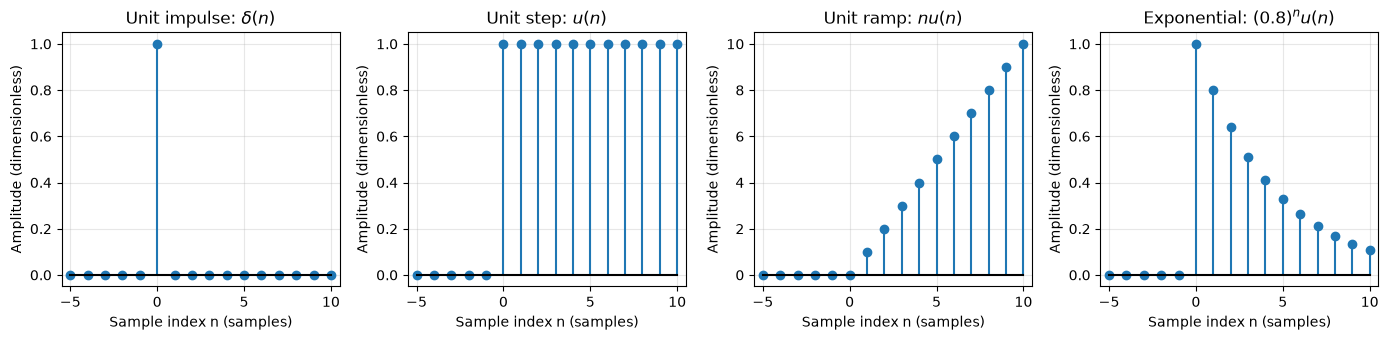

Known-value checks passed for all four sequences.


In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)       # 1 only at n = 0
step = (n >= 0).astype(float)        # 1 for every n >= 0
ramp = n * step                     # n for n >= 0, otherwise 0
expo = 0.8**n * step                # causal, decaying exponential

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, x_sequence, title in zip(
    axes,
    [delta, step, ramp, expo],
    [r'Unit impulse: $\delta(n)$', r'Unit step: $u(n)$',
     r'Unit ramp: $n u(n)$', r'Exponential: $(0.8)^n u(n)$'],
):
    ax.stem(n, x_sequence, basefmt='k-')
    ax.set_title(title)
    ax.set_xlabel('Sample index n (samples)')
    ax.set_ylabel('Amplitude (dimensionless)')
    ax.set_xlim(-5.5, 10.5)
    ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / 'task_1_1_sequences.png', dpi=160)
plt.show()

assert delta.sum() == 1 and delta[n == 0].item() == 1
assert np.all(step[n < 0] == 0) and np.all(step[n >= 0] == 1)
assert ramp[n == 10].item() == 10
assert np.isclose(expo[n == 1].item(), 0.8)
print('Known-value checks passed for all four sequences.')

The impulse has only one nonzero sample at $n=0$. The step changes from 0
to 1 at $n=0$. The ramp increases by 1 per sample for $n\geq0$. The
exponential starts at 1 and decreases by a factor of 0.8 each sample.
All four are zero for $n<0$.

## Task 1.2 — Change the parameters

### Exponentials: $a^n u(n)$

Use the same integer range as Task 1.1 and plot each value of $a$ separately.

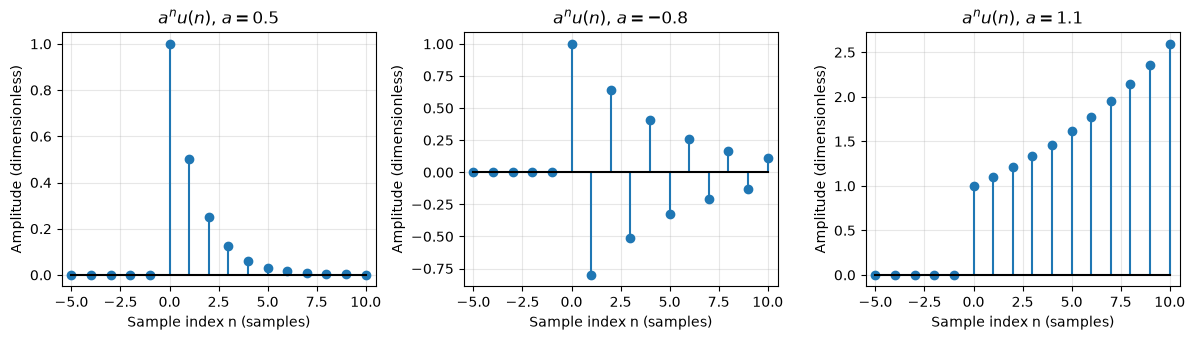

a =  0.5: x(0) = 1, x(1) = 0.5, x(10) = 0.000977
a = -0.8: x(0) = 1, x(1) = -0.8, x(10) = 0.107374
a =  1.1: x(0) = 1, x(1) = 1.1, x(10) = 2.593742


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    xa = a**n * step
    ax.stem(n, xa, basefmt='k-')
    ax.set_title(fr'$a^n u(n)$, $a={a}$')
    ax.set_xlabel('Sample index n (samples)')
    ax.set_ylabel('Amplitude (dimensionless)')
    ax.set_xlim(-5.5, 10.5)
    ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / 'task_1_2_exponentials.png', dpi=160)
plt.show()

for a in [0.5, -0.8, 1.1]:
    print(f'a = {a:4.1f}: x(0) = 1, x(1) = {a:.1f}, x(10) = {a**10:.6f}')

- $a=0.5$: positive samples decay rapidly toward zero.
- $a=-0.8$: the sign alternates while the magnitude decays toward zero.
- $a=1.1$: positive samples grow without bound as $n$ increases. The short
  plot shows the beginning of this growth.

### Cosines for $0\leq n\leq40$

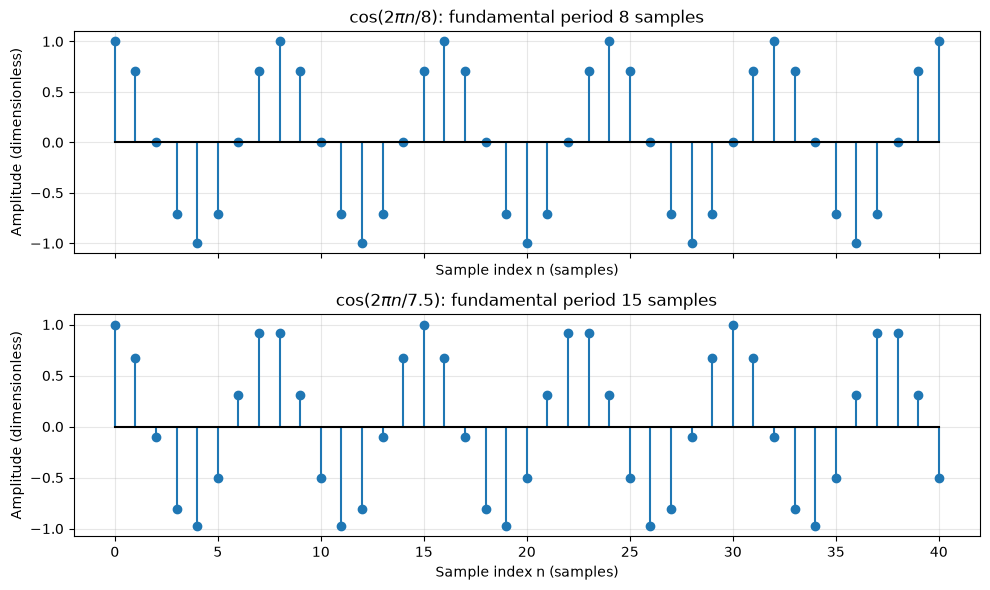

Verified fundamental periods: 8 samples and 15 samples.


In [4]:
n_cos = np.arange(41)
cos8 = np.cos(2 * np.pi * n_cos / 8)
cos75 = np.cos(2 * np.pi * n_cos / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, values, title in zip(
    axes, [cos8, cos75],
    [r'$\cos(2\pi n/8)$: fundamental period 8 samples',
     r'$\cos(2\pi n/7.5)$: fundamental period 15 samples'],
):
    ax.stem(n_cos, values, basefmt='k-')
    ax.set_title(title)
    ax.set_xlabel('Sample index n (samples)')
    ax.set_ylabel('Amplitude (dimensionless)')
    ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / 'task_1_2_cosines.png', dpi=160)
plt.show()

# Compare all overlapping samples separated by each proposed period.
assert np.allclose(cos8[8:], cos8[:-8], rtol=0, atol=1e-12)
assert np.allclose(cos75[15:], cos75[:-15], rtol=0, atol=1e-12)
assert not np.allclose(cos75[8:], cos75[:-8], rtol=0, atol=1e-12)
for samples, period in [(cos8, 8), (cos75, 15)]:
    assert not any(
        np.allclose(samples[k:], samples[:-k], rtol=0, atol=1e-12)
        for k in range(1, period)
    )
print('Verified fundamental periods: 8 samples and 15 samples.')

**Both sequences repeat exactly in mathematics.** A discrete-time cosine
$\cos(\omega_0 n)$ is periodic when an integer $N>0$ satisfies
$\omega_0N=2\pi k$ for an integer $k$.

For the first cosine, $\omega_0/(2\pi)=1/8$, so the smallest period is
$N=8$ samples (one cycle). For the second, $1/7.5=2/15$, so the smallest
period is $N=15$ samples (two cycles). A period of 7.5 samples is impossible
on an integer sample grid, but that does not make this second sequence
aperiodic. The manual's singular wording should not be read as saying only
one repeats. Numerical comparisons use a tolerance for floating-point error.

## Task 1.3 — Working with audio

For your own recording, save 3–5 seconds of speech as `my_voice.wav` beside
this notebook, or upload that WAV to the Colab Files panel. The following cell
loads the file if present; otherwise it uses the manual's exact fallback:
a 2-second, 440 Hz sine at 16,000 Hz with an exponentially decaying envelope.
The fallback is clearly identified in all outputs.

Audio samples are converted to floating point before taking absolute values
to avoid signed-integer overflow. Stereo channels are averaged. Unsigned
8-bit PCM is centered about zero, and silence is left at zero.

Synthetic fallback: 440 Hz decaying sine (not a voice recording)
fs = 16000 Hz, duration = 2.00 s, samples = 32000
Peak absolute amplitude = 0.499657


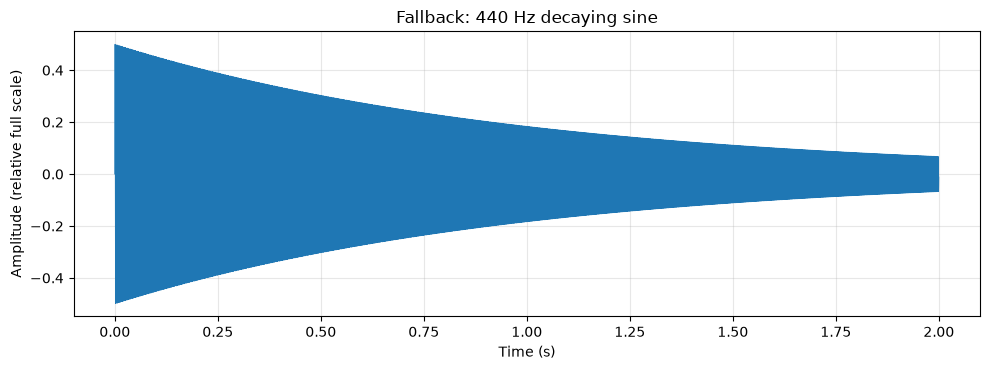

In [5]:
def mono_normalize(raw):
    raw = np.asarray(raw)
    if raw.ndim not in (1, 2) or raw.size == 0:
        raise ValueError('Expected a nonempty mono or multichannel WAV.')
    mono = raw.astype(np.float64)
    if raw.dtype == np.uint8:
        mono -= 128.0
    if mono.ndim == 2:
        mono = mono.mean(axis=1)
    if not np.all(np.isfinite(mono)):
        raise ValueError('The WAV contains nonfinite sample values.')
    peak = np.max(np.abs(mono))
    return mono / peak if peak > 0 else mono


fname = Path('my_voice.wav')
using_recording = fname.is_file()
if using_recording:
    fs, raw = wavfile.read(fname)
    x = mono_normalize(raw)
    audio_source = f'Phone/user WAV: {fname.name}'
else:
    fs = 16000
    t_fallback = np.arange(0, 2, 1 / fs)
    x = 0.5 * np.sin(2 * np.pi * 440 * t_fallback) * np.exp(-t_fallback)
    audio_source = 'Synthetic fallback: 440 Hz decaying sine (not a voice recording)'

t = np.arange(len(x)) / fs
duration = len(x) / fs
print(audio_source)
print(f'fs = {fs} Hz, duration = {duration:.2f} s, samples = {len(x)}')
print(f'Peak absolute amplitude = {np.max(np.abs(x)):.6f}')
if using_recording and not 3 <= duration <= 5:
    print('The supplied recording is outside the requested 3-5 second range.')

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t, x, linewidth=0.6)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude (relative full scale)')
ax.set_title('My voice recording' if using_recording else 'Fallback: 440 Hz decaying sine')
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / 'task_1_3_audio.png', dpi=160)
plt.show()

# A visible notebook audio player; listen using headphones.
display(Audio(x, rate=fs, normalize=False))

### Write and read back the audio

The output is a mono, signed 16-bit PCM WAV. Multiplication by 32767 converts
the floating-point range to PCM sample values without wrapping. Reading it
back checks its rate, sample count, and quantization error.

In [6]:
audio_out = output_dir / 'lab0_processed.wav'
pcm = np.rint(np.clip(x, -1, 1) * 32767).astype(np.int16)
wavfile.write(audio_out, fs, pcm)
fs_readback, pcm_readback = wavfile.read(audio_out)
assert fs_readback == fs
assert pcm_readback.shape == x.shape
assert np.array_equal(pcm_readback, pcm)
max_error = np.max(np.abs(x - pcm_readback.astype(float) / 32767))
assert max_error <= 0.5 / 32767 + 1e-12
print(f'Wrote {audio_out}: {fs_readback} Hz, mono, signed 16-bit PCM.')
print(f'Maximum write/read error = {max_error:.8f} (relative amplitude).')

# Known-answer checks for normalization and the permitted fallback.
assert np.array_equal(mono_normalize(np.zeros(8, dtype=np.int16)), np.zeros(8))
assert np.array_equal(mono_normalize(np.array([128, 128], dtype=np.uint8)), [0, 0])
assert np.allclose(mono_normalize(np.array([-32768, 0, 32767], dtype=np.int16)),
                   [-1, 0, 32767 / 32768])
assert np.array_equal(mono_normalize(np.array([[1000, -1000]], dtype=np.int16)), [0])
if not using_recording:
    assert fs == 16000 and len(x) == 32000 and duration == 2.0
    peak_bin = np.argmax(np.abs(np.fft.rfft(x)))
    measured_frequency = np.fft.rfftfreq(len(x), d=1 / fs)[peak_bin]
    assert np.isclose(measured_frequency, 440.0)
    print(f'Fallback frequency check: FFT peak = {measured_frequency:.1f} Hz.')
print('Audio normalization and WAV read/write checks passed.')

Wrote outputs\lab0_processed.wav: 16000 Hz, mono, signed 16-bit PCM.
Maximum write/read error = 0.00001526 (relative amplitude).
Fallback frequency check: FFT peak = 440.0 Hz.
Audio normalization and WAV read/write checks passed.


With the fallback, the required printed result is **16,000 Hz**, **2.00 s**,
and **32,000 mono samples**. Its envelope decreases as $0.5e^{-t}$, so the
sound is a fading 440 Hz tone. That is a prediction from the signal formula;
personal listening observations must be added after listening. No personal
voice recording or listening session is claimed.

When a user WAV is present, the printed measurements and plot are computed
from that file instead. Run all cells after changing the recording.

## Task 1.4 — The same in Octave (optional)

The companion file **`week01_lab0.m`** implements all four sequences from
Task 1.1 with labeled stem plots and known-value checks. Run it in GNU Octave
with `run('week01_lab0.m')`. It saves `outputs/task_1_4_octave.png`.

| Python / NumPy | Octave / MATLAB | Meaning |
| --- | --- | --- |
| `np.arange(-5, 11)` | `-5:10` | Integers from -5 through 10 |
| `(n >= 0).astype(float)` | `double(n >= 0)` | Convert logical values to numbers |
| `n * step` | `n .* step` | Element-wise product |
| `0.8**n` | `0.8 .^ n` | Element-wise exponentiation |
| `plt.subplots(1, 4)` | `subplot(1, 4, k)` | Arrange subplots |
| `ax.stem(n, x)` | `stem(n, x)` | Plot discrete samples |
| Index starts at 0 | Index starts at 1 | Array indexing convention |

The script is supplied, but no Octave or MATLAB executable was available in
this environment, so execution in those applications remains unverified.

## Task 1.5 — Repository and submission

The manual permits a GitHub, GitLab, **or local** Git repository. The local
repository for this work is:

`C:\Users\amins\Downloads\DSP\COU07506-labs`

Repository name: **COU07506-labs**. The Week 1 notebook, Octave script,
generated figures, generated WAV, and reproducible notebook source are
included in the local commit. No remote URL exists yet. This local path is
the repository reference for the permitted local option. To inspect it, run
`git log -1 --oneline` and `git status --short` in that folder.

**Submission steps requiring your account or personal action:**

1. Fill in the title cell and rename the notebook to
   `COU07506_Week01_<RegNo>.ipynb`.
2. Personalize the pre-lab examples, review the code, and optionally replace
   the permitted fallback with your 3–5 second voice WAV.
3. Restart the kernel and run all cells; confirm that no errors appear.
4. Show the Task 1.1–1.3 plots and audio measurements to the instructor for
   Checkpoint 1. Leave its sign-off box empty until the instructor signs.
5. Commit your final personalized notebook. Upload it to DIT-eLMS and verify
   the submission confirmation. **The eLMS upload has not been performed.**
6. Form a mini-project group of 3–5 students and list two possible topics in
   the eLMS forum. Suggested discussion topics: (a) speech noise reduction
   using digital filters; (b) detecting abnormal machine vibration from
   recorded sensor signals. No group membership or forum post is claimed.

## Analysis questions

### 1. What is the sampling rate of your phone recording? How many numbers store one minute in mono?

No phone WAV was supplied, so its actual sampling rate is **unknown**. For
any loaded WAV, the exact rate is `fs` printed in Task 1.3. In mono, one
minute contains $N=60f_s$ sample values. The following cell computes the
answer from the audio actually used. With the fallback, $f_s=16,000$ Hz and
$N=960,000$ numbers. These are fallback values, not measured phone values.
For comparison, a 44,100 Hz phone file needs 2,646,000 mono numbers per
minute, while a 48,000 Hz file needs 2,880,000. The number of bytes also
depends on the sample representation; a 16-bit mono sample takes 2 bytes,
excluding headers and metadata.

In [7]:
one_minute_samples = 60 * int(fs)
one_minute_pcm_bytes = 2 * one_minute_samples
print(f'Audio source: {audio_source}')
print(f'Sampling rate: {fs:,} Hz')
print(f'One minute in mono: {one_minute_samples:,} sample values')
print(f'At 16-bit PCM: {one_minute_pcm_bytes:,} bytes of sample data (without WAV header)')

Audio source: Synthetic fallback: 440 Hz decaying sine (not a voice recording)
Sampling rate: 16,000 Hz
One minute in mono: 960,000 sample values
At 16-bit PCM: 1,920,000 bytes of sample data (without WAV header)


### 2. Why is a stem plot more appropriate than a continuous line for $x(n)$?

A discrete-time sequence is defined only at integer indices. A stem plot
shows each sample at its own index without suggesting values between
samples. Connecting lines can be useful for viewing long audio waveforms,
but they are only a visual aid, not extra measured samples.

### 3. Which system property would $h(n)=(1.1)^n u(n)$ violate?

An LTI system with this impulse response would violate **bounded-input,
bounded-output (BIBO) stability**. An LTI system is BIBO stable exactly when
its impulse response is absolutely summable. Here,
$\sum_{n=0}^{\infty}|h(n)|=\sum_{n=0}^{\infty}1.1^n$ diverges.
The unit impulse is itself a bounded input, yet the corresponding output
$h(n)$ grows without bound, directly demonstrating the violation.

## AI-use statement

**AI tool used:** OpenAI Codex (ChatGPT).  
**Used for:** creating the Lab 0 notebook and companion Octave script,
explaining Tasks 1.1–1.5, drafting the pre-lab examples and analysis answers,
and preparing the local Git repository.  
**Verification performed:** compare the impulse, step, ramp, and exponential
against known values; verify cosine repetition at 8 and 15 samples and check
smaller candidate periods; verify the 440 Hz fallback using its FFT; check
the audio sample count, duration, normalization edge cases, and WAV write/read
quantization error; execute the Python notebook from top to bottom.
The Octave script has not been run in Octave/MATLAB. The personal recording,
instructor sign-off, and eLMS submission have not been verified.

**Student declaration — complete personally after reviewing the notebook:**  
[ ] I confirm that I understand and can explain all submitted code.